[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bhargav312005/CA-3-predictive-analytics/blob/main/ECommerce_Return_Prediction_CA3.ipynb)

# E-Commerce Product Return Prediction Using Machine Learning

| | |
|---|---|
| **Course** | Predictive Analytics — CA3 |
| **Student** | Bhargav Sor |
| **PRN** | 23070521031 |
| **Programme** | B.Tech CSE, Semester VII, Section A |
| **Institution** | Symbiosis Institute of Technology, Nagpur |
| **Dataset** | Kaggle *E-Commerce Dataset* (hakdevelopment/e-commerce-dataset) |

---

**How to run:** Execute all cells top to bottom (`Kernel → Restart & Run All`).  
All figures, metrics, and output files are regenerated automatically from the raw CSV files.  
No results are hard-coded.


## Running on Google Colab

This notebook runs on **Google Colab** and on **VS Code / local Python** without modification.

### Files you must upload to Colab

Upload all of the following to the Colab session storage (the folder icon in the left sidebar → *Upload*):  

| File | Required? | Purpose |
|---|---|---|
| `data/train.csv` | **Yes** | Labelled training data (200,000 orders) |
| `data/test.csv` | **Yes** | Unlabelled test data (50,000 orders) |
| `data/sample_submission.csv` | **Yes** | Submission template |

### Expected upload structure

```
/content/
    ECommerce_Return_Prediction_CA3.ipynb   ← this notebook
    data/
        train.csv
        test.csv
        sample_submission.csv
```

Output files (`results/submission.csv`, `results/test_probabilities.csv`) and figures  
will be written to `results/` relative to wherever the notebook is running.  
On Colab you can download them from the file browser after execution.

### Do NOT install
- `jupyter`, `nbconvert`, or `ipykernel` — Colab provides its own kernel.
- A virtual environment (`.venv`) — not needed on Colab.

The dependency installation cell below installs only what Colab does not provide by default.


## Dependency Installation

This cell installs packages that are **not** pre-installed on Google Colab.  
On a local machine with all packages already present, the cell is a no-op (packages are already satisfied).


In [1]:
# Install packages not available by default on Google Colab.
# On local environments these are already installed — pip will skip them.
import importlib, subprocess, sys

def _ensure(pkg, import_name=None):
    name = import_name or pkg
    if importlib.util.find_spec(name) is None:
        print(f'Installing {pkg}...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
    else:
        print(f'{pkg}: already available')

_ensure('xgboost')
_ensure('shap')
print('Dependency check complete.')


xgboost: already available
shap: already available
Dependency check complete.


## 1. Executive Summary

This report presents an end-to-end Knowledge Discovery in Databases (KDD) workflow for predicting whether an e-commerce order will be returned.  
Product returns impose significant costs on e-commerce businesses: increased logistics expense, reverse-supply-chain overhead, reduced net revenue, and environmental waste.  
A predictive model that identifies high-return-risk orders before or immediately after delivery enables proactive interventions — targeted post-purchase communication, quality checks for high-risk categories, and smarter return-policy management.

The analysis uses a Kaggle labelled dataset of **200,000 orders** with 14 predictor features.  
Five supervised classifiers are compared against a majority-class baseline using **stratified 5-fold cross-validated ROC-AUC**.  
**XGBoost** achieves the highest cross-validated ROC-AUC and is selected as the final model.

On an untouched 40,000-order holdout set, XGBoost achieves ROC-AUC ≈ 0.596, accuracy ≈ 57%, and F1 ≈ 0.493.  
While flat classification accuracy is only modestly above the 52.5% baseline, the model is most valuable as a **risk-ranking tool**:  
the top 10% of orders ranked by model score have a return rate approximately 1.33× the overall rate — enabling cost-effective targeted interventions.


## 2. Problem Identification / Problem Definition

### Background

E-commerce return rates are rising. Returns create reverse logistics costs, inventory write-downs, repackaging expenses, and carbon footprint.  
A model that flags high-risk orders early gives operations teams a chance to intervene.

### Problem Statement

> *Can a machine-learning model predict, from features available at or after the point of order, whether a customer will return a product?*

### Task type

**Binary supervised classification**: target `returned` ∈ {0, 1}.  
The training set contains labelled historical orders (known outcomes).  
The goal is to learn a mapping from input features → return probability that generalises to new, unseen orders.


## 3. Objective

1. Load and profile the training and test datasets.
2. Identify and handle physically impossible (invalid) values.
3. Conduct EDA to understand feature distributions and return-rate associations.
4. Perform statistical hypothesis tests (Mann-Whitney U, Chi-square, Cramér's V).
5. Engineer five domain-relevant features from the raw variables.
6. Build and tune six models: majority-class baseline, Logistic Regression, Decision Tree, Random Forest, Histogram Gradient Boosting, XGBoost.
7. Select the best model by stratified 5-fold cross-validated ROC-AUC.
8. Evaluate on an untouched 20% holdout partition.
9. Compare post-delivery vs checkout-time prediction scenarios.
10. Analyse decision thresholds and produce a risk-ranking (lift) analysis.
11. Interpret the model via LR odds ratios, permutation importance, and SHAP.
12. Generate final predictions for `test.csv` and save output files.


## 4. Prediction Moment and Success Criteria

### Two prediction scenarios

| Scenario | `delivery_delay_days` | When usable |
|---|---|---|
| **Post-delivery (PRIMARY)** | **Included** | After delivery, before the return window closes |
| Checkout-time (secondary) | Excluded | At the moment of purchase |

**Why `delivery_delay_days` is excluded from the checkout scenario:**  
`delivery_delay_days` records how many days late (or early) an order arrived relative to the promised date.  
This value is only known *after* the parcel is delivered — including it at checkout would constitute **temporal feature leakage**.  
The checkout-time scenario therefore explicitly drops this feature.

The **post-delivery scenario is the primary modelling scenario** throughout this project.

### Success criteria

| Criterion | Target |
|---|---|
| Primary metric | CV ROC-AUC > 0.50 (random baseline) |
| Lift | > 1.0 in the top-10% risk group |
| Practical utility | Model usable as a risk-ranking tool for business |


## 5. Setup — Libraries, Paths, Constants


In [2]:
import sys, warnings, time, os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_predict,
    cross_validate, train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

# ── Inline display for Colab and Jupyter ─────────────────────────────────
# %matplotlib inline is automatically active on Colab; plt.show() handles
# both environments, so no explicit magic is needed here.

# ── Portable path configuration ──────────────────────────────────────────
# Works correctly whether the notebook is opened:
#   (a) from the project root  (VS Code, local Jupyter)
#   (b) from notebooks/        (some local Jupyter setups)
#   (c) from /content/         (Google Colab — project cloned or uploaded there)

_cwd = Path.cwd()
if _cwd.name == 'notebooks':            # case (b): running inside notebooks/
    BASE_DIR = _cwd.parent
elif (_cwd / 'data').exists():          # case (a) or (c): data/ sits here
    BASE_DIR = _cwd
else:                                     # Colab opened from /content/ with repo cloned below it
    _project_dirs = [p for p in _cwd.iterdir() if p.is_dir() and (p / 'data').is_dir()]
    if len(_project_dirs) == 1:
        BASE_DIR = _project_dirs[0]
    else:                                 # fallback: try one level up
        BASE_DIR = _cwd.parent if (_cwd.parent / 'data').is_dir() else _cwd

DATA_DIR    = BASE_DIR / 'data'
OUT_DIR     = BASE_DIR / 'results'
FIG_DIR     = OUT_DIR  / 'figures'

# Create output directories (safe to call even if they already exist)
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True,  exist_ok=True)
FIG_DIR.mkdir(parents=True,  exist_ok=True)

# ── Constants ─────────────────────────────────────────────────────────────
SEED   = 42          # random seed — used everywhere for reproducibility
TARGET = 'returned'
ID_COL = 'order_id'
POST   = True        # PRIMARY scenario: post-delivery (delivery_delay_days INCLUDED)
OP_THR = 0.5         # operating decision threshold

# ── Colour palette ────────────────────────────────────────────────────────
BLUE, ORANGE, AQUA     = '#2a78d6', '#eb6834', '#1baf7a'
YELLOW, MAGENTA        = '#eda100', '#e87ba4'
INK, INK2, GRID, SURF  = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.edgecolor': INK2,
    'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'legend.frameon': False, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
})

print(f'Python {sys.version.split()[0]}')
print(f'BASE_DIR  : {BASE_DIR.resolve()}')
print(f'DATA_DIR  : {DATA_DIR.resolve()}')
print(f'OUT_DIR   : {OUT_DIR.resolve()}')
print(f'FIG_DIR   : {FIG_DIR.resolve()}')
print()
# Verify data files are present
for fname in ['train.csv', 'test.csv', 'sample_submission.csv']:
    path = DATA_DIR / fname
    status = 'FOUND' if path.exists() else 'MISSING — upload this file'
    print(f'  {fname:30s}: {status}')


Python 3.13.2
BASE_DIR  : C:\Users\Lenovo\Desktop\PREDICTIVE PROJECT\CODE
DATA_DIR  : C:\Users\Lenovo\Desktop\PREDICTIVE PROJECT\CODE\data
OUT_DIR   : C:\Users\Lenovo\Desktop\PREDICTIVE PROJECT\CODE\results
FIG_DIR   : C:\Users\Lenovo\Desktop\PREDICTIVE PROJECT\CODE\results\figures

  train.csv                     : FOUND
  test.csv                      : FOUND
  sample_submission.csv         : FOUND


In [3]:
NUM_RAW = [
    'customer_age', 'product_price', 'discount_percent', 'product_rating',
    'past_purchase_count', 'past_return_rate', 'delivery_delay_days',
    'session_length_minutes', 'num_product_views'
]
CAT = ['device_type', 'product_category', 'shipping_method', 'payment_method']
BIN = ['used_coupon']

VALID_RULES = {
    'product_price':          (0,    None),
    'discount_percent':       (0,    100),
    'product_rating':         (1,    5),
    'past_return_rate':       (0,    1),
    'session_length_minutes': (0,    None),
    'num_product_views':      (0,    None),
}
print('Column roles and validation rules defined.')


Column roles and validation rules defined.


### Pipeline helper classes and functions

All pipeline logic is defined in this self-contained notebook.


In [4]:
from sklearn.base import BaseEstimator, TransformerMixin


class Cleaner(BaseEstimator, TransformerMixin):
    """KDD step 3: convert physically impossible values to NaN."""
    def __init__(self, enabled=True):
        self.enabled = enabled

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        if self.enabled:
            for col, (lo, hi) in VALID_RULES.items():
                if col in X.columns:
                    bad = (X[col] < lo) if lo is not None else pd.Series(False, index=X.index)
                    if hi is not None:
                        bad = bad | (X[col] > hi)
                    X.loc[bad, col] = np.nan
        return X


class FeatureEngineer(BaseEstimator, TransformerMixin):
    """KDD step 4: row-level domain features — no cross-row statistics, no leakage."""
    def __init__(self, post_delivery=True):
        self.post_delivery = post_delivery

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X['final_price']            = X['product_price'] * (1 - X['discount_percent'] / 100)
        X['discount_amount']        = X['product_price'] * X['discount_percent'] / 100
        X['expected_prior_returns'] = X['past_purchase_count'] * X['past_return_rate']
        X['views_per_minute']       = X['num_product_views'] / X['session_length_minutes'].clip(lower=1)
        if self.post_delivery:
            X['is_late'] = (X['delivery_delay_days'] > 0).astype(float)
        elif 'delivery_delay_days' in X.columns:
            X = X.drop(columns=['delivery_delay_days'])
        return X


ENG = ['final_price', 'discount_amount', 'expected_prior_returns', 'views_per_minute']


def numeric_cols(post_delivery=True):
    base = [c for c in NUM_RAW if post_delivery or c != 'delivery_delay_days']
    return base + ENG + (['is_late'] if post_delivery else []) + BIN


def make_pipeline(model, post_delivery=True, clean=True, scale=False):
    num = numeric_cols(post_delivery)
    num_steps = [('impute', SimpleImputer(strategy='median', add_indicator=True))]
    if scale:
        num_steps.append(('scale', StandardScaler()))
    pre = ColumnTransformer([
        ('num', Pipeline(num_steps), num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False,
                              drop='first' if scale else None), CAT),
    ], verbose_feature_names_out=False)
    return Pipeline([
        ('clean', Cleaner(clean)),
        ('fe', FeatureEngineer(post_delivery)),
        ('pre', pre),
        ('model', model),
    ])


def metrics_at(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {
        'accuracy':  accuracy_score(y, yhat),
        'precision': precision_score(y, yhat, zero_division=0),
        'recall':    recall_score(y, yhat),
        'f1':        f1_score(y, yhat),
        'roc_auc':   roc_auc_score(y, p),
        'pr_auc':    average_precision_score(y, p),
    }


print('Pipeline helpers defined: Cleaner, FeatureEngineer, make_pipeline, metrics_at')
print(f'Numeric cols (post-delivery): {numeric_cols(True)}')


Pipeline helpers defined: Cleaner, FeatureEngineer, make_pipeline, metrics_at
Numeric cols (post-delivery): ['customer_age', 'product_price', 'discount_percent', 'product_rating', 'past_purchase_count', 'past_return_rate', 'delivery_delay_days', 'session_length_minutes', 'num_product_views', 'final_price', 'discount_amount', 'expected_prior_returns', 'views_per_minute', 'is_late', 'used_coupon']


## 6. Dataset Selection and Understanding

**Source:** Kaggle *E-Commerce Dataset* (`hakdevelopment/e-commerce-dataset`)

| File | Role |
|---|---|
| `train.csv` | 200,000 labelled orders — contains `returned` target |
| `test.csv` | 50,000 unlabelled orders — no `returned` column |
| `sample_submission.csv` | Submission template — columns `ID` and `returned` |


In [5]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test  = pd.read_csv(DATA_DIR / 'test.csv')
sub   = pd.read_csv(DATA_DIR / 'sample_submission.csv')

print(f'train.csv         : {train.shape[0]:>7,} rows x {train.shape[1]} columns')
print(f'test.csv          : {test.shape[0]:>7,} rows x {test.shape[1]} columns')
print(f'sample_submission : {sub.shape[0]:>7,} rows x {sub.shape[1]} columns')
print()
print('Columns (train):', list(train.columns))


train.csv         : 200,000 rows x 16 columns
test.csv          :  50,000 rows x 15 columns
sample_submission :  50,000 rows x 2 columns

Columns (train): ['customer_age', 'product_price', 'discount_percent', 'product_rating', 'past_purchase_count', 'past_return_rate', 'delivery_delay_days', 'session_length_minutes', 'num_product_views', 'device_type', 'product_category', 'shipping_method', 'payment_method', 'used_coupon', 'returned', 'order_id']


In [6]:
print('=== Integrity Checks ===')
print(f'Missing values  - train : {train.isna().sum().sum()}')
print(f'Missing values  - test  : {test.isna().sum().sum()}')
print(f'Duplicate rows (train)  : {train.duplicated().sum()}')
print(f'Duplicate order IDs     : {train[ID_COL].duplicated().sum()}')
print(f'Train/test ID overlap   : {len(set(train[ID_COL]) & set(test[ID_COL]))}')
print(f'Test has target col     : {TARGET in test.columns}')
print(f'Sub IDs match test IDs  : {(sub["ID"].values == test[ID_COL].values).all()}')
print()
print('Summary: dataset arrives clean (no NaN, no duplicates).')
print('Invalid entries are encoded as out-of-range numbers — identified next.')


=== Integrity Checks ===
Missing values  - train : 0
Missing values  - test  : 0


Duplicate rows (train)  : 0
Duplicate order IDs     : 0
Train/test ID overlap   : 0
Test has target col     : False


Sub IDs match test IDs  : True

Summary: dataset arrives clean (no NaN, no duplicates).
Invalid entries are encoded as out-of-range numbers — identified next.


In [7]:
train[NUM_RAW + BIN].describe().round(3)


,customer_age,product_price,discount_percent,product_rating,past_purchase_count,past_return_rate,delivery_delay_days,session_length_minutes,num_product_views,used_coupon
count,200000.000,200000.000,200000.000,200000.000,200000.00,200000.000,200000.000,200000.000,200000.000,200000.000
mean,56.480,37.984,42.872,2.813,9.62,0.215,0.625,77.406,14.654,0.615
std,17.953,45.627,21.510,1.220,3.14,0.137,2.331,36.394,12.659,0.487
min,10.000,-183.292,-7.541,0.445,1.00,-0.061,-9.050,-11.010,-5.000,0.000
25%,44.000,6.877,25.849,1.789,8.00,0.118,-0.752,48.995,3.000,0.000
50%,58.000,24.461,42.945,2.819,9.00,0.191,0.519,81.562,13.000,1.000
75%,72.000,53.356,62.642,3.810,10.00,0.282,1.897,108.209,25.000,1.000
max,87.000,855.079,78.792,5.453,26.00,0.866,7.961,137.653,44.000,1.000


## 7. Data Dictionary

| Feature | Type | Availability | Valid Range | Description |
|---|---|---|---|---|
| `customer_age` | Numeric | At checkout | >= 18 (flag only) | Customer age in years |
| `product_price` | Numeric | At checkout | >= 0 | Listed product price |
| `discount_percent` | Numeric | At checkout | 0-100 | Discount applied (%) |
| `product_rating` | Numeric | At checkout | 1-5 | Average product rating |
| `past_purchase_count` | Numeric | At checkout | - | Number of prior purchases |
| `past_return_rate` | Numeric | At checkout* | 0-1 | Customer's historical return rate |
| `delivery_delay_days` | Numeric | **After delivery** | - | Days late (negative = early) |
| `session_length_minutes` | Numeric | At checkout | >= 0 | Browse session length (min) |
| `num_product_views` | Numeric | At checkout | >= 0 | Product pages viewed |
| `device_type` | Categorical | At checkout | mobile/desktop/tablet | Device used |
| `product_category` | Categorical | At checkout | 6 categories | Product category |
| `shipping_method` | Categorical | At checkout | standard/express/same_day | Shipping selected |
| `payment_method` | Categorical | At checkout | 4 options | Payment used |
| `used_coupon` | Binary | At checkout | 0/1 | 1 = coupon used |
| `order_id` | Identifier | - | - | **Excluded from modelling** |
| `returned` | **Target** | After return window | 0/1 | 0 = kept, 1 = returned |

**Why `order_id` is excluded:** Arbitrary database key — no predictive relationship to returns.  
Single-feature AUC check confirms this (AUC ~0.499 = no signal).

*`past_return_rate` is assumed computed from the customer's earlier orders only.


## 8. Data Quality / Physically Impossible Values

Several numeric features have well-defined valid ranges based on real-world meaning.  
Values outside these ranges are **physically impossible**:

| Feature | Valid Range | Reason |
|---|---|---|
| `product_price` | >= 0 | A price cannot be negative |
| `discount_percent` | 0 to 100 | A percentage must lie in [0, 100] |
| `product_rating` | 1 to 5 | Ratings are on a 1-5 scale |
| `past_return_rate` | 0 to 1 | A proportion must lie in [0, 1] |
| `session_length_minutes` | >= 0 | A duration cannot be negative |
| `num_product_views` | >= 0 | A count cannot be negative |

**Root cause:** Unknown — likely data pipeline bugs or placeholder values.  
Return rates among invalid rows (~47.5%) are similar to the overall rate, suggesting random errors, not systematic patterns.


In [8]:
anomaly_rows = {}
for col, (lo, hi) in VALID_RULES.items():
    bad = (train[col] < lo) if lo is not None else pd.Series(False, index=train.index)
    if hi is not None:
        bad = bad | (train[col] > hi)
    rate = train.loc[bad, TARGET].mean() if bad.any() else float('nan')
    anomaly_rows[col] = {
        'valid_range':             f"{lo if lo is not None else '-inf'} to {hi if hi is not None else '+inf'}",
        'invalid_count':           int(bad.sum()),
        'invalid_pct':             round(bad.mean() * 100, 2),
        'return_rate_if_invalid':  round(rate, 4) if not pd.isna(rate) else 'N/A',
    }

young = train['customer_age'] < 18
anomaly_rows['customer_age < 18 (flag only, kept)'] = {
    'valid_range': 'flag only',
    'invalid_count': int(young.sum()),
    'invalid_pct': round(young.mean() * 100, 2),
    'return_rate_if_invalid': round(train.loc[young, TARGET].mean(), 4),
}

anom_df = pd.DataFrame(anomaly_rows).T
print(anom_df[['valid_range', 'invalid_count', 'invalid_pct', 'return_rate_if_invalid']].to_string())

any_bad = np.zeros(len(train), dtype=bool)
for col, (lo, hi) in VALID_RULES.items():
    b = (train[col] < lo).to_numpy() if lo is not None else np.zeros(len(train), bool)
    if hi is not None:
        b = b | (train[col] > hi).to_numpy()
    any_bad = any_bad | b
print(f'\nRows with >=1 invalid value: {any_bad.sum():,} ({any_bad.mean():.1%} of training set)')


                                    valid_range invalid_count invalid_pct return_rate_if_invalid
product_price                         0 to +inf         27285       13.64                 0.4377
discount_percent                       0 to 100          1686        0.84                 0.4152
product_rating                           1 to 5         18111        9.06                 0.4628
past_return_rate                         0 to 1          2220        1.11                 0.4221
session_length_minutes                0 to +inf          1487        0.74                 0.5151
num_product_views                     0 to +inf         21443       10.72                 0.5069
customer_age < 18 (flag only, kept)   flag only          2109        1.05                 0.4941

Rows with >=1 invalid value: 64,079 (32.0% of training set)


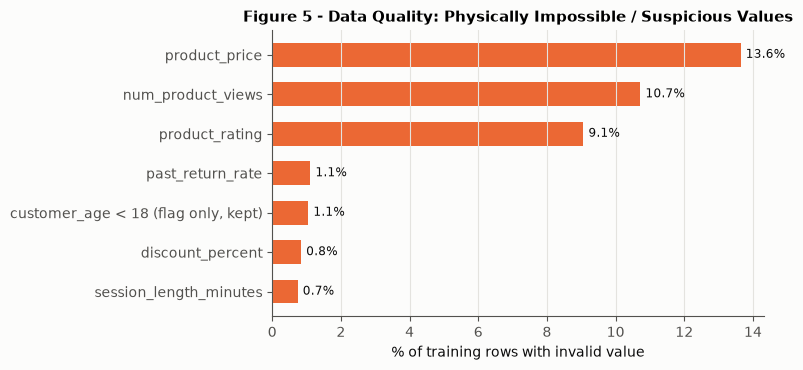

In [9]:
# Figure 05 — Invalid values prevalence
an = anom_df.sort_values('invalid_pct')
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(an.index, an['invalid_pct'].astype(float), color=ORANGE, height=0.6)
for i, v in enumerate(an['invalid_pct'].astype(float)):
    ax.text(v + 0.15, i, f'{v:.1f}%', va='center', fontsize=8.5, color=INK)
ax.set_xlabel('% of training rows with invalid value')
ax.set_title('Figure 5 - Data Quality: Physically Impossible / Suspicious Values')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.savefig(FIG_DIR / '05_invalid_values.png')
plt.show()


## 9. Data Preprocessing

Invalid values are **converted to NaN** rather than deleting entire rows (which would discard 32% of training data).  
After conversion:
- **Median imputation** replaces NaN (robust to skewed distributions).
- **Missing-value indicator flags** append binary 0/1 columns recording which values were originally invalid.

Imputation medians are fitted only on training data within each CV fold — no leakage.


In [10]:
sample_raw   = train[list(VALID_RULES.keys())].head(8).copy()
sample_clean = Cleaner(enabled=True).transform(sample_raw)
print('Before cleaning (first 8 rows):')
print(sample_raw.to_string())
print('\nAfter cleaning (invalid -> NaN):')
print(sample_clean.to_string())


Before cleaning (first 8 rows):
   product_price  discount_percent  product_rating  past_return_rate  session_length_minutes  num_product_views
0      11.666137         43.559601        1.933533          0.331408                3.273029                 26
1      31.378967         66.526039        0.690237          0.105203              130.513123                  8
2      25.460603         20.762374        2.347620          0.236683               92.780917                 -2
3      13.517170         25.669260        2.033596          0.410038              103.004177                  7
4      75.771311         15.527927        4.907556          0.123565              100.752658                  6
5      12.503790         50.310553        1.300992          0.193033              103.860035                 22
6      13.970847         43.429092        1.501649          0.299652              125.522620                  6
7      -2.326689         68.232052        4.628188          0.516389    

## 10. Cleaning Ablation

| Condition | Description |
|---|---|
| **Cleaned** | Invalid -> NaN + median impute + missing indicator |
| **Raw** | No cleaning; invalid values passed directly to model |

Results are shown in Section 24 (after model selection).


## 11. Feature Engineering

Five new features constructed from raw columns using row-level arithmetic only (no leakage):

| Feature | Formula | Business meaning |
|---|---|---|
| `final_price` | `product_price * (1 - discount_percent/100)` | Actual price paid |
| `discount_amount` | `product_price * discount_percent/100` | Monetary saving |
| `expected_prior_returns` | `past_purchase_count * past_return_rate` | Estimated past returns |
| `views_per_minute` | `num_product_views / max(session_length_minutes, 1)` | Browsing intensity |
| `is_late` *(post-delivery only)* | `1 if delivery_delay_days > 0 else 0` | Late delivery flag |


In [11]:
sample_fe = train[[
    'product_price', 'discount_percent', 'past_purchase_count',
    'past_return_rate', 'num_product_views', 'session_length_minutes',
    'delivery_delay_days'
]].head(5).copy()
sample_fe['final_price']            = sample_fe['product_price'] * (1 - sample_fe['discount_percent'] / 100)
sample_fe['discount_amount']        = sample_fe['product_price'] * sample_fe['discount_percent'] / 100
sample_fe['expected_prior_returns'] = sample_fe['past_purchase_count'] * sample_fe['past_return_rate']
sample_fe['views_per_minute']       = sample_fe['num_product_views'] / sample_fe['session_length_minutes'].clip(1)
sample_fe['is_late']                = (sample_fe['delivery_delay_days'] > 0).astype(int)
print('Engineered features (5 sample rows):')
sample_fe[['final_price','discount_amount','expected_prior_returns','views_per_minute','is_late']].round(4)


Engineered features (5 sample rows):


,final_price,discount_amount,expected_prior_returns,views_per_minute,is_late
0,6.5844,5.0817,2.6513,7.9437,0
1,10.5038,20.8752,0.9468,0.0613,1
2,20.1744,5.2862,3.3136,-0.0216,1
3,10.0474,3.4698,3.6903,0.0680,1
4,64.0056,11.7657,1.1121,0.0596,0


## 12. Leakage / Feature Availability Review

| Feature | At checkout | Post-delivery | Notes |
|---|---|---|---|
| customer_age | Yes | Yes | Customer profile |
| product_price | Yes | Yes | Order line |
| discount_percent | Yes | Yes | Order line |
| product_rating | Yes | Yes | Product listing |
| past_purchase_count | Yes | Yes | Customer history |
| past_return_rate | Yes* | Yes* | Customer history |
| **delivery_delay_days** | **No** | **Yes** | **Only known after delivery** |
| session_length_minutes | Yes | Yes | Browsing session |
| num_product_views | Yes | Yes | Browsing session |
| device_type | Yes | Yes | Browsing session |
| product_category | Yes | Yes | Order line |
| shipping_method | Yes | Yes | Order line |
| payment_method | Yes | Yes | Order line |
| used_coupon | Yes | Yes | Order line |
| **returned** | **No** | **No** | **TARGET - never a feature** |
| **order_id** | **No** | **No** | **Identifier - excluded** |


In [12]:
y_all = train[TARGET]
id_auc = roc_auc_score(y_all, train[ID_COL])
print(f'order_id single-feature AUC: {id_auc:.4f}  (expected ~0.5 = no signal)')


order_id single-feature AUC: 0.4988  (expected ~0.5 = no signal)


## 13. Exploratory Data Analysis

EDA is performed on the full labelled training set before the train/holdout split.  
No supervised model fitting occurs here, so no holdout leakage is possible.


Not Returned (0): 105,081  (52.54%)
Returned     (1):  94,919  (47.46%)
Overall return rate: 0.4746


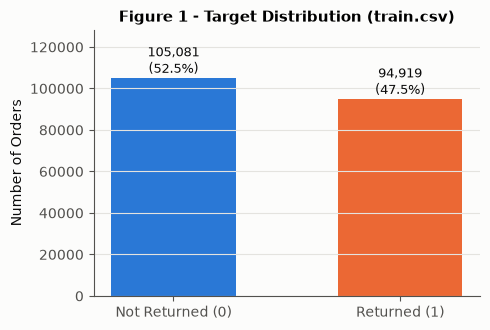

Dataset is approximately balanced. ROC-AUC is used as primary metric
because it evaluates ranking quality across all thresholds.


In [13]:
vc           = train[TARGET].value_counts().sort_index()
overall_rate = train[TARGET].mean()
print(f'Not Returned (0): {vc[0]:>7,}  ({vc[0]/len(train):.2%})')
print(f'Returned     (1): {vc[1]:>7,}  ({vc[1]/len(train):.2%})')
print(f'Overall return rate: {overall_rate:.4f}')

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.bar(['Not Returned (0)', 'Returned (1)'], [vc[0], vc[1]], color=[BLUE, ORANGE], width=0.55)
for i, v in enumerate([vc[0], vc[1]]):
    ax.text(i, v + 400, f'{v:,}\n({v/len(train):.1%})', ha='center', va='bottom', fontsize=9, color=INK)
ax.set_ylabel('Number of Orders')
ax.set_title('Figure 1 - Target Distribution (train.csv)')
ax.set_ylim(0, max(vc.values) * 1.22)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig(FIG_DIR / '01_target_balance.png')
plt.show()
print('Dataset is approximately balanced. ROC-AUC is used as primary metric')
print('because it evaluates ranking quality across all thresholds.')


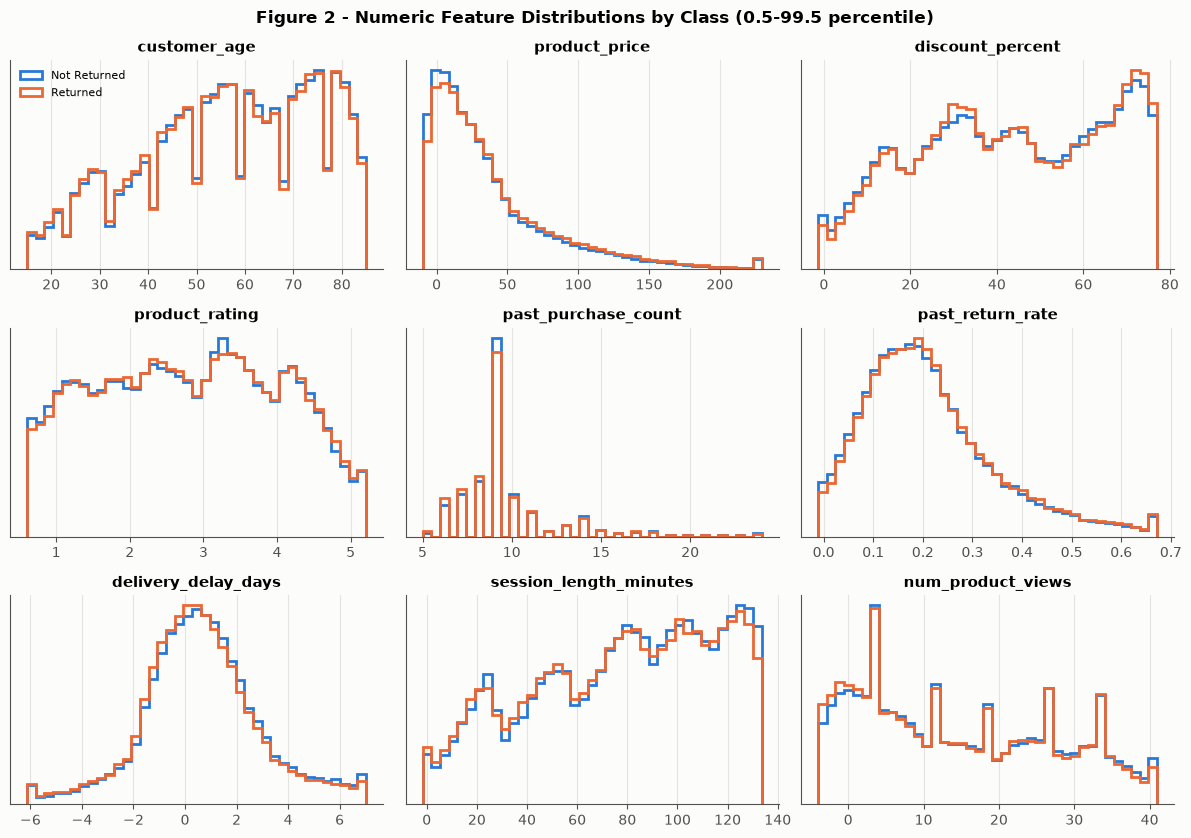

In [14]:
# Figure 02 — Numeric distributions by class
fig, axes = plt.subplots(3, 3, figsize=(12, 8.5))
for ax, col in zip(axes.ravel(), NUM_RAW):
    lo, hi = np.percentile(train[col].dropna(), [0.5, 99.5])
    bins = np.linspace(lo, hi, 40)
    ax.hist(train.loc[y_all==0, col].clip(lo,hi), bins=bins, density=True,
            histtype='step', lw=2, color=BLUE, label='Not Returned')
    ax.hist(train.loc[y_all==1, col].clip(lo,hi), bins=bins, density=True,
            histtype='step', lw=2, color=ORANGE, label='Returned')
    ax.set_title(col); ax.set_yticks([])
axes[0,0].legend(loc='upper left', fontsize=8)
fig.suptitle('Figure 2 - Numeric Feature Distributions by Class (0.5-99.5 percentile)', fontweight='bold')
fig.tight_layout()
plt.savefig(FIG_DIR / '02_numeric_by_class.png')
plt.show()


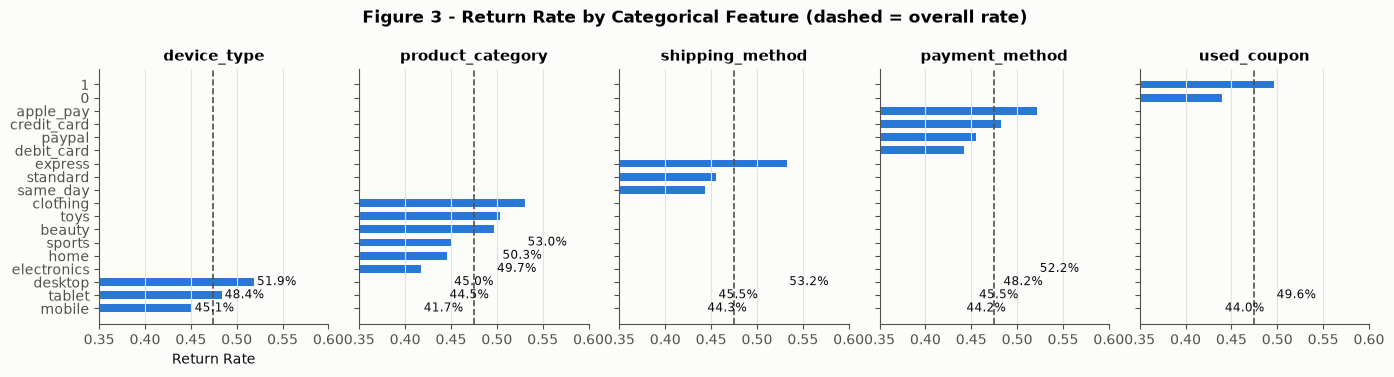

In [15]:
# Figure 03 — Return rate by categorical feature
fig, axes = plt.subplots(1, 5, figsize=(14, 3.8), sharey=True)
for ax, col in zip(axes, CAT + BIN):
    rates = train.groupby(col)[TARGET].mean().sort_values()
    ax.barh([str(i) for i in rates.index], rates.values, color=BLUE, height=0.6)
    ax.axvline(overall_rate, color=INK2, lw=1.2, ls='--')
    for i, v in enumerate(rates.values):
        ax.text(v + 0.003, i, f'{v:.1%}', va='center', fontsize=8.5, color=INK)
    ax.set_xlim(0.35, 0.60); ax.set_title(col); ax.grid(axis='y', visible=False)
axes[0].set_xlabel('Return Rate')
fig.suptitle('Figure 3 - Return Rate by Categorical Feature (dashed = overall rate)', fontweight='bold')
fig.tight_layout()
plt.savefig(FIG_DIR / '03_return_rate_by_category.png')
plt.show()


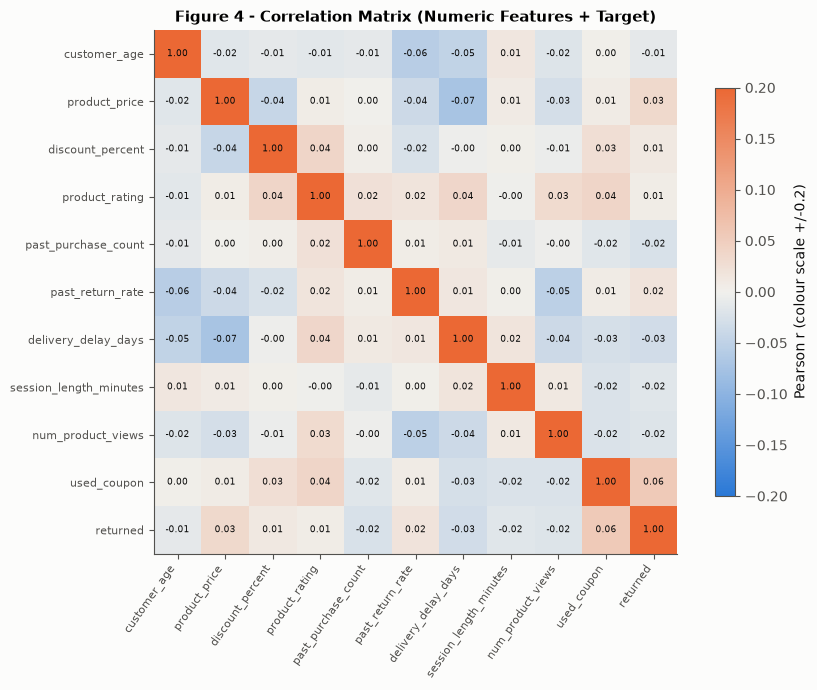

Max |correlation with target|: 0.0550 (feature: used_coupon)
All feature-target correlations |r| < 0.06 — individually weak predictors.


In [16]:
# Figure 04 — Correlation heatmap
corr = train[NUM_RAW + BIN + [TARGET]].corr().round(3)
div_cmap = LinearSegmentedColormap.from_list('div', [BLUE, '#f1f0ec', ORANGE])
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr.values, cmap=div_cmap, vmin=-0.2, vmax=0.2)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=55, ha='right', fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center', fontsize=6.5, color=INK)
fig.colorbar(im, ax=ax, shrink=0.78, label='Pearson r (colour scale +/-0.2)')
ax.set_title('Figure 4 - Correlation Matrix (Numeric Features + Target)')
plt.tight_layout()
plt.savefig(FIG_DIR / '04_correlation_heatmap.png')
plt.show()
print(f'Max |correlation with target|: {corr[TARGET].drop(TARGET).abs().max():.4f} '
      f'(feature: {corr[TARGET].drop(TARGET).abs().idxmax()})')
print('All feature-target correlations |r| < 0.06 — individually weak predictors.')


## 14. Hypothesis Testing

| Test | Applied to | Purpose |
|---|---|---|
| Mann-Whitney U | Numeric | Non-parametric test for distributional difference |
| Point-biserial r | Numeric | Linear association with binary target |
| Single-feature AUC | Numeric | Discriminative power alone |
| Chi-square | Categorical | Association with target |
| Cramer's V | Categorical | Standardised effect size |

Statistical significance (low p-value) does **not** imply causation or guarantee usefulness in a multi-feature model.


In [17]:
num_tests = []
for col in NUM_RAW + BIN:
    a = train.loc[y_all==1, col].dropna()
    b = train.loc[y_all==0, col].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    r, _ = stats.pointbiserialr(y_all, train[col])
    auc  = roc_auc_score(y_all, train[col])
    num_tests.append({'feature': col, 'mean_returned': round(float(a.mean()),4),
                      'mean_kept': round(float(b.mean()),4), 'point_biserial_r': round(float(r),4),
                      'mannwhitney_p': float(p), 'single_feature_auc': round(float(auc),4)})
num_df = pd.DataFrame(num_tests).set_index('feature')
print('Numeric tests:')
print(num_df.to_string())


Numeric tests:
                        mean_returned  mean_kept  point_biserial_r  mannwhitney_p  single_feature_auc
feature                                                                                              
customer_age                  56.2645    56.6738           -0.0114   9.276410e-07              0.4937
product_price                 39.6321    36.4957            0.0343   1.729139e-71              0.5231
discount_percent              43.1380    42.6318            0.0118   5.143430e-07              0.5065
product_rating                 2.8187     2.8075            0.0046   5.812551e-02              0.5024
past_purchase_count            9.5419     9.6910           -0.0237   1.672563e-47              0.4820
past_return_rate               0.2177     0.2128            0.0180   1.040288e-16              0.5107
delivery_delay_days            0.5476     0.6950           -0.0316   5.142983e-48              0.4812
session_length_minutes        76.7426    78.0055           -0.0173 

In [18]:
print('Categorical tests:\n')
for col in CAT:
    ct  = pd.crosstab(train[col], y_all)
    chi = stats.chi2_contingency(ct)
    v   = np.sqrt(chi.statistic / (len(train) * (min(ct.shape) - 1)))
    rates = train.groupby(col)[TARGET].mean().round(4).to_dict()
    print(f'{col}')
    print(f"  chi2={chi.statistic:.1f}, dof={chi.dof}, p={chi.pvalue:.2e}, Cramer's V={v:.4f}")
    print(f'  Return rates: {rates}\n')


Categorical tests:

device_type
  chi2=643.2, dof=2, p=2.09e-140, Cramer's V=0.0567
  Return rates: {'desktop': 0.5191, 'mobile': 0.4512, 'tablet': 0.4838}

product_category
  chi2=1169.2, dof=5, p=1.40e-250, Cramer's V=0.0765
  Return rates: {'beauty': 0.4972, 'clothing': 0.5305, 'electronics': 0.4173, 'home': 0.4454, 'sports': 0.4504, 'toys': 0.5031}

shipping_method
  chi2=969.1, dof=2, p=3.58e-211, Cramer's V=0.0696
  Return rates: {'express': 0.5322, 'same_day': 0.4429, 'standard': 0.4551}

payment_method
  chi2=739.6, dof=3, p=5.50e-160, Cramer's V=0.0608
  Return rates: {'apple_pay': 0.5217, 'credit_card': 0.4821, 'debit_card': 0.4418, 'paypal': 0.4554}



## 15. Train / Holdout Split

**80/20 stratified split** — holdout is set aside completely and not used for any modelling decisions.  
Stratification preserves the class proportion (~47.5% returned) in both partitions.


In [19]:
X = train.drop(columns=[TARGET, ID_COL])
y = train[TARGET].values

X_tr, X_ho, y_tr, y_ho = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print(f'Training partition : {len(X_tr):>7,} rows  (return rate: {y_tr.mean():.4f})')
print(f'Holdout  partition : {len(X_ho):>7,} rows  (return rate: {y_ho.mean():.4f})')
print(f'Overall return rate: {y.mean():.4f}')


Training partition : 160,000 rows  (return rate: 0.4746)
Holdout  partition :  40,000 rows  (return rate: 0.4746)
Overall return rate: 0.4746


## 16. Preprocessing Pipeline

```
Pipeline:
  1. Cleaner          -> converts impossible values to NaN
  2. FeatureEngineer  -> adds 5 engineered features
  3. ColumnTransformer:
       Numeric branch : SimpleImputer(median, add_indicator=True) [+ StandardScaler for LR]
       Categorical    : OneHotEncoder(handle_unknown='ignore')
  4. Model
```

Fitting inside CV folds prevents leakage of imputation statistics.


In [20]:
demo_pipe = make_pipeline(XGBClassifier(n_estimators=5, random_state=SEED),
                          post_delivery=True, clean=True, scale=False)
print(demo_pipe)
print(f'\nNumeric input features (post-delivery): {len(numeric_cols(True))}')


Pipeline(steps=[('clean', Cleaner()), ('fe', FeatureEngineer()),
                ('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median'))]),
                                                  ['customer_age',
                                                   'product_price',
                                                   'discount_percent',
                                                   'product_rating',
                                                   'past_purchase_count',
                                                   'past_return_rate',
                                                   'delivery_delay_days',
                                                   'session_length_minutes',
 

## 17. Model Development

| Model | Type | Key characteristic |
|---|---|---|
| Majority-class baseline | Trivial | Always predicts most frequent class |
| Logistic Regression | Linear | Interpretable; requires scaling |
| Decision Tree | Non-linear | Interpretable; prone to overfitting |
| Random Forest | Ensemble (bagging) | Reduces variance via averaging |
| Histogram Gradient Boosting | Ensemble (boosting) | Efficient on mixed types |
| **XGBoost** | Ensemble (boosting) | State-of-the-art on tabular data |


## 18. Hyperparameter Tuning

GridSearchCV with 3-fold stratified CV, ROC-AUC scoring, on a 50k stratified subsample.  
(Subsample used to keep tuning runtime reasonable on both local machines and Colab.)


In [21]:
candidates = {
    'Logistic Regression': (
        LogisticRegression(max_iter=2000),
        {'model__C': [0.01, 0.1, 1, 10]}, True),
    'Decision Tree': (
        DecisionTreeClassifier(random_state=SEED),
        {'model__max_depth': [4, 6, 8, 10, 12], 'model__min_samples_leaf': [50, 200]}, False),
    'Random Forest': (
        # n_jobs=-1: use all available CPUs — safe on both Colab and local
        RandomForestClassifier(n_estimators=200, max_features='sqrt',
                               n_jobs=-1, random_state=SEED),
        {'model__max_depth': [8, 12, 16], 'model__min_samples_leaf': [20, 50]}, False),
    'Hist Gradient Boosting': (
        HistGradientBoostingClassifier(max_iter=400, early_stopping=True, random_state=SEED),
        {'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [15, 31],
         'model__l2_regularization': [0.0, 1.0]}, False),
    'XGBoost': (
        # n_jobs=1: avoids multiprocessing conflicts on Colab / Windows
        XGBClassifier(n_estimators=300, subsample=0.8, colsample_bytree=0.8,
                      tree_method='hist', eval_metric='logloss',
                      n_jobs=1, random_state=SEED),
        {'model__max_depth': [3, 5], 'model__learning_rate': [0.05, 0.1]}, False),
}

X_sub, _, y_sub, _ = train_test_split(
    X_tr, y_tr, train_size=min(50_000, len(X_tr)-1), stratify=y_tr, random_state=SEED
)
cv3    = StratifiedKFold(3, shuffle=True, random_state=SEED)
tuned  = {}
tuning = {}

print('Tuning on 50k subsample, 3-fold CV (ROC-AUC)...')
for name, (est, grid, scale) in candidates.items():
    t0 = time.time()
    # n_jobs=1 for GridSearchCV: avoids multiprocessing fork issues on Colab
    gs = GridSearchCV(make_pipeline(est, POST, True, scale), grid,
                      scoring='roc_auc', cv=cv3, n_jobs=1)
    gs.fit(X_sub, y_sub)
    tuned[name]  = (gs.best_estimator_, scale)
    tuning[name] = {
        'best_params':   {k.replace('model__',''):v for k,v in gs.best_params_.items()},
        'tuning_cv_auc': round(gs.best_score_, 5),
        'seconds':       round(time.time()-t0, 1),
    }
    print(f'  {name:30s}  AUC={gs.best_score_:.5f}  '
          f'params={tuning[name]["best_params"]}  ({tuning[name]["seconds"]}s)')

print('\nBest params per model:')
for name, info in tuning.items():
    print(f'  {name:30s}: {info["best_params"]}')


Tuning on 50k subsample, 3-fold CV (ROC-AUC)...


  Logistic Regression             AUC=0.58857  params={'C': 0.1}  (2.0s)


  Decision Tree                   AUC=0.57186  params={'max_depth': 6, 'min_samples_leaf': 200}  (9.3s)


  Random Forest                   AUC=0.58732  params={'max_depth': 8, 'min_samples_leaf': 50}  (14.6s)


  Hist Gradient Boosting          AUC=0.58659  params={'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_leaf_nodes': 15}  (8.9s)


  XGBoost                         AUC=0.58829  params={'learning_rate': 0.05, 'max_depth': 3}  (16.7s)

Best params per model:
  Logistic Regression           : {'C': 0.1}
  Decision Tree                 : {'max_depth': 6, 'min_samples_leaf': 200}
  Random Forest                 : {'max_depth': 8, 'min_samples_leaf': 50}
  Hist Gradient Boosting        : {'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_leaf_nodes': 15}
  XGBoost                       : {'learning_rate': 0.05, 'max_depth': 3}


## 19. 5-Fold Cross-Validation

Stratified 5-fold CV on the full 160,000-row training partition.

**Why ROC-AUC as primary metric?**  
ROC-AUC is threshold-independent — it measures ranking quality across all thresholds.  
It is robust to the near-balanced class distribution (~47.5% vs 52.5%) and ideal for model selection before the operating threshold is decided.


In [22]:
cv5     = StratifiedKFold(5, shuffle=True, random_state=SEED)
scoring = {'accuracy':'accuracy','precision':'precision','recall':'recall',
           'f1':'f1','roc_auc':'roc_auc','pr_auc':'average_precision'}

models = {'Baseline (majority class)': make_pipeline(DummyClassifier(strategy='most_frequent'), POST)}
models.update({n: m for n,(m,_) in tuned.items()})

cvres = {}
print('Running 5-fold CV on 160k rows...')
for name, pipe in models.items():
    t0 = time.time()
    r  = cross_validate(clone(pipe), X_tr, y_tr, cv=cv5, scoring=scoring, n_jobs=1)
    cvres[name] = {k: {'mean': float(r[f'test_{k}'].mean()),
                        'std':  float(r[f'test_{k}'].std())} for k in scoring}
    print(f'  {name:35s}  AUC={cvres[name]["roc_auc"]["mean"]:.5f} '
          f'+/- {cvres[name]["roc_auc"]["std"]:.5f}  ({time.time()-t0:.0f}s)')

ranked = sorted([n for n in cvres if not n.startswith('Baseline')],
                key=lambda n: cvres[n]['roc_auc']['mean'], reverse=True)
best = ranked[0]
print(f'\n*** Best model (CV ROC-AUC): {best} ***')
print(f'    AUC = {cvres[best]["roc_auc"]["mean"]:.5f} +/- {cvres[best]["roc_auc"]["std"]:.5f}')


Running 5-fold CV on 160k rows...


  Baseline (majority class)            AUC=0.50000 +/- 0.00000  (2s)


  Logistic Regression                  AUC=0.58946 +/- 0.00386  (3s)


  Decision Tree                        AUC=0.57741 +/- 0.00286  (6s)


  Random Forest                        AUC=0.59092 +/- 0.00381  (16s)


  Hist Gradient Boosting               AUC=0.59380 +/- 0.00324  (6s)


  XGBoost                              AUC=0.59454 +/- 0.00345  (21s)

*** Best model (CV ROC-AUC): XGBoost ***
    AUC = 0.59454 +/- 0.00345


## 20. Model Comparison


In [23]:
order_models = ['Baseline (majority class)', 'Logistic Regression', 'Decision Tree',
                'Random Forest', 'Hist Gradient Boosting', 'XGBoost']
rows = []
for name in order_models:
    m = cvres[name]
    rows.append({'Model': name,
        'Accuracy':  f"{m['accuracy']['mean']:.4f} +/- {m['accuracy']['std']:.4f}",
        'Precision': f"{m['precision']['mean']:.4f}",
        'Recall':    f"{m['recall']['mean']:.4f}",
        'F1':        f"{m['f1']['mean']:.4f}",
        'ROC-AUC':   f"{m['roc_auc']['mean']:.5f} +/- {m['roc_auc']['std']:.5f}",
        'PR-AUC':    f"{m['pr_auc']['mean']:.5f}",
    })
cv_table = pd.DataFrame(rows).set_index('Model')
print('5-Fold CV Results:')
print(cv_table.to_string())


5-Fold CV Results:
                                    Accuracy Precision  Recall      F1              ROC-AUC   PR-AUC
Model                                                                                               
Baseline (majority class)  0.5254 +/- 0.0000    0.0000  0.0000  0.0000  0.50000 +/- 0.00000  0.47459
Logistic Regression        0.5662 +/- 0.0031    0.5550  0.4331  0.4865  0.58946 +/- 0.00386  0.55542
Decision Tree              0.5587 +/- 0.0032    0.5535  0.3641  0.4390  0.57741 +/- 0.00286  0.54110
Random Forest              0.5657 +/- 0.0016    0.5675  0.3574  0.4385  0.59092 +/- 0.00381  0.55790
Hist Gradient Boosting     0.5700 +/- 0.0023    0.5604  0.4356  0.4902  0.59380 +/- 0.00324  0.56141
XGBoost                    0.5700 +/- 0.0021    0.5602  0.4374  0.4912  0.59454 +/- 0.00345  0.56174


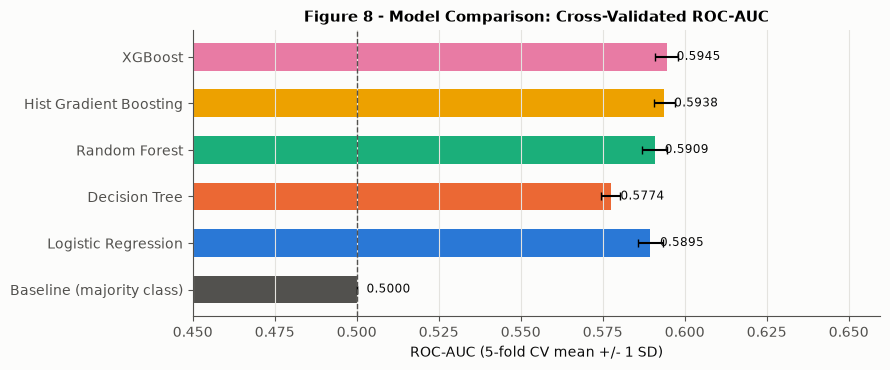

Selected model: XGBoost


In [24]:
# Figure 08 — Model comparison
colours_list = [INK2, BLUE, ORANGE, AQUA, YELLOW, MAGENTA]
colours_map  = dict(zip(order_models[1:], colours_list[1:]))
fig, ax = plt.subplots(figsize=(9, 3.8))
means = [cvres[n]['roc_auc']['mean'] for n in order_models]
sds   = [cvres[n]['roc_auc']['std']  for n in order_models]
ax.barh(order_models, means, xerr=sds, color=colours_list, height=0.6, capsize=3)
for i, v in enumerate(means):
    ax.text(v + 0.003, i, f'{v:.4f}', va='center', fontsize=8.5, color=INK)
ax.set_xlim(0.45, max(means)+0.065)
ax.axvline(0.5, color=INK2, lw=1, ls='--')
ax.set_xlabel('ROC-AUC (5-fold CV mean +/- 1 SD)')
ax.set_title('Figure 8 - Model Comparison: Cross-Validated ROC-AUC')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.savefig(FIG_DIR / '08_model_comparison.png')
plt.show()
print(f'Selected model: {best}')


## 21. Holdout Set Evaluation

Each model is re-trained on the full 160k training partition and evaluated on the **untouched 40k holdout**.


In [25]:
ho_results  = {}
probs       = {}
fitted_best = None
fitted_lr   = None

print('Fitting on 160k training; evaluating on 40k holdout...')
for name, pipe in models.items():
    m = clone(pipe).fit(X_tr, y_tr)
    p = m.predict_proba(X_ho)[:, 1]
    probs[name]      = p
    ho_results[name] = metrics_at(y_ho, p, OP_THR)
    if name == best:                   fitted_best = m
    if name == 'Logistic Regression':  fitted_lr   = m
    print(f'  {name:35s}  AUC={ho_results[name]["roc_auc"]:.5f}  '
          f'F1={ho_results[name]["f1"]:.4f}  Acc={ho_results[name]["accuracy"]:.4f}')

ho_results['Baseline (always predict returned)'] = metrics_at(y_ho, np.ones(len(y_ho)), OP_THR)
ho_results['Baseline (always predict returned)']['roc_auc'] = 0.5
print('Holdout evaluation complete.')


Fitting on 160k training; evaluating on 40k holdout...


  Baseline (majority class)            AUC=0.50000  F1=0.0000  Acc=0.5254


  Logistic Regression                  AUC=0.59077  F1=0.4900  Acc=0.5672


  Decision Tree                        AUC=0.57556  F1=0.4392  Acc=0.5555


  Random Forest                        AUC=0.59318  F1=0.4476  Acc=0.5697


  Hist Gradient Boosting               AUC=0.59437  F1=0.4905  Acc=0.5696


  XGBoost                              AUC=0.59543  F1=0.4935  Acc=0.5710
Holdout evaluation complete.


In [26]:
ho_rows = []
for name in order_models:
    m = ho_results[name]
    ho_rows.append({'Model': name,
        'Accuracy': f"{m['accuracy']:.4f}", 'Precision': f"{m['precision']:.4f}",
        'Recall': f"{m['recall']:.4f}", 'F1': f"{m['f1']:.4f}",
        'ROC-AUC': f"{m['roc_auc']:.5f}", 'PR-AUC': f"{m['pr_auc']:.5f}",
    })
ho_table = pd.DataFrame(ho_rows).set_index('Model')
print('Holdout Results (threshold = 0.50):')
print(ho_table.to_string())
print(f'\nBest model holdout ROC-AUC : {ho_results[best]["roc_auc"]:.5f}')
print(f'Best model holdout Accuracy: {ho_results[best]["accuracy"]:.4f}')
print(f'Best model holdout F1      : {ho_results[best]["f1"]:.4f}')


Holdout Results (threshold = 0.50):
                          Accuracy Precision  Recall      F1  ROC-AUC   PR-AUC
Model                                                                         
Baseline (majority class)   0.5254    0.0000  0.0000  0.0000  0.50000  0.47460
Logistic Regression         0.5672    0.5558  0.4381  0.4900  0.59077  0.55724
Decision Tree               0.5555    0.5473  0.3668  0.4392  0.57556  0.53856
Random Forest               0.5697    0.5728  0.3673  0.4476  0.59318  0.55967
Hist Gradient Boosting      0.5696    0.5597  0.4365  0.4905  0.59437  0.56090
XGBoost                     0.5710    0.5612  0.4404  0.4935  0.59543  0.56162

Best model holdout ROC-AUC : 0.59543
Best model holdout Accuracy: 0.5710
Best model holdout F1      : 0.4935


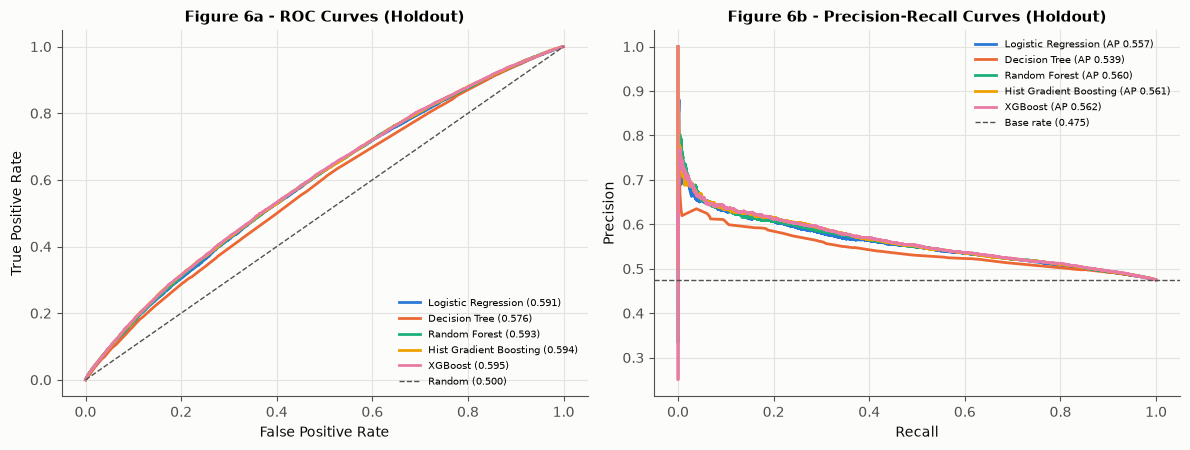

In [27]:
# Figure 06 — ROC and PR curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for name, c in colours_map.items():
    fpr, tpr, _ = roc_curve(y_ho, probs[name])
    pr,  rc,  _ = precision_recall_curve(y_ho, probs[name])
    axes[0].plot(fpr, tpr, lw=2, color=c, label=f'{name} ({ho_results[name]["roc_auc"]:.3f})')
    axes[1].plot(rc,  pr,  lw=2, color=c, label=f'{name} (AP {ho_results[name]["pr_auc"]:.3f})')
axes[0].plot([0,1],[0,1], ls='--', color=INK2, lw=1, label='Random (0.500)')
axes[1].axhline(y_ho.mean(), ls='--', color=INK2, lw=1, label=f'Base rate ({y_ho.mean():.3f})')
axes[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate',
            title='Figure 6a - ROC Curves (Holdout)')
axes[1].set(xlabel='Recall', ylabel='Precision',
            title='Figure 6b - Precision-Recall Curves (Holdout)')
for a in axes:
    a.legend(fontsize=7.5, loc='lower right' if a is axes[0] else 'upper right')
fig.tight_layout()
plt.savefig(FIG_DIR / '06_roc_pr_curves.png')
plt.show()


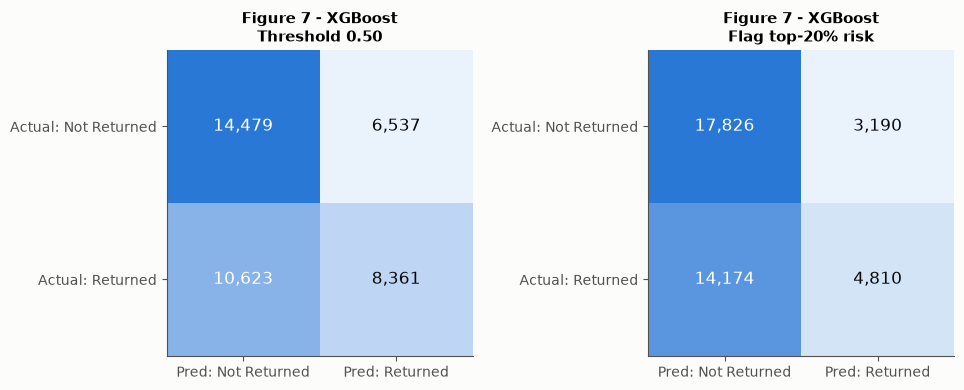

CM @ 0.5: TN=14,479 FP=6,537 FN=10,623 TP=8,361
Top-20% policy (cutoff >= 0.5422): TN=17,826 FP=3,190 FN=14,174 TP=4,810


In [28]:
# Figure 07 — Confusion matrices
cm05 = confusion_matrix(y_ho, (probs[best] >= OP_THR).astype(int))
k20  = np.quantile(probs[best], 0.80)
cmk  = confusion_matrix(y_ho, (probs[best] >= k20).astype(int))

div_cmap2 = LinearSegmentedColormap.from_list('seq', ['#eaf2fc', BLUE])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0))
for ax, cm, title in [(axes[0], cm05, f'Threshold {OP_THR:.2f}'),
                       (axes[1], cmk,  'Flag top-20% risk')]:
    ax.imshow(cm, cmap=div_cmap2); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i,j]:,}', ha='center', va='center',
                    fontsize=12, color=INK if cm[i,j] < cm.max()*0.6 else 'white')
    ax.set_xticks([0,1]); ax.set_xticklabels(['Pred: Not Returned','Pred: Returned'])
    ax.set_yticks([0,1]); ax.set_yticklabels(['Actual: Not Returned','Actual: Returned'])
    ax.set_title(f'Figure 7 - {best}\n{title}')
fig.tight_layout()
plt.savefig(FIG_DIR / '07_confusion_matrix.png')
plt.show()
print(f'CM @ {OP_THR}: TN={cm05[0,0]:,} FP={cm05[0,1]:,} FN={cm05[1,0]:,} TP={cm05[1,1]:,}')
print(f'Top-20% policy (cutoff >= {k20:.4f}): TN={cmk[0,0]:,} FP={cmk[0,1]:,} FN={cmk[1,0]:,} TP={cmk[1,1]:,}')


## 22. Threshold Analysis

### Why the F1-optimal threshold was rejected

The F1-optimal threshold (~0.34) flags approximately **95.7% of all orders** as predicted returns.  
This collapses to the trivial rule: *predict everything as returned*.  
The OOF F1 at this threshold (~0.645) is barely higher than predicting all orders returned (~0.644).  

**Operating threshold stays at 0.50.**  
For business use: **top-k% risk ranking** rather than hard binary classification.


In [29]:
oof = cross_val_predict(clone(tuned[best][0]), X_tr, y_tr, cv=cv5, method='predict_proba')[:, 1]

prec_oof, rec_oof, thr_oof = precision_recall_curve(y_tr, oof)
f1s_oof  = 2*prec_oof[:-1]*rec_oof[:-1] / np.clip(prec_oof[:-1]+rec_oof[:-1], 1e-12, None)
best_thr = float(thr_oof[np.argmax(f1s_oof)])

print(f'F1-optimal threshold (OOF)      : {best_thr:.4f}')
print(f'OOF F1 at F1-optimal threshold  : {f1s_oof.max():.4f}')
print(f'Share flagged at F1-optimal     : {(oof >= best_thr).mean():.2%}')
print(f'OOF F1 at threshold = 0.50      : {f1_score(y_tr, oof >= 0.5):.4f}')
print(f'OOF F1 if ALL orders flagged    : {f1_score(y_tr, np.ones_like(y_tr)):.4f}')
print()
print('VERDICT: F1-optimal threshold flags ~96% of orders (near-trivial).')
print('Operating threshold stays at 0.50.')


F1-optimal threshold (OOF)      : 0.3462
OOF F1 at F1-optimal threshold  : 0.6451
Share flagged at F1-optimal     : 94.74%
OOF F1 at threshold = 0.50      : 0.4913
OOF F1 if ALL orders flagged    : 0.6437

VERDICT: F1-optimal threshold flags ~96% of orders (near-trivial).
Operating threshold stays at 0.50.


In [30]:
print(f'Threshold sensitivity ({best}, holdout):\n')
thr_rows = []
for thr in [0.40, 0.45, 0.50, 0.55, 0.60]:
    yhat = (probs[best] >= thr).astype(int)
    thr_rows.append({'Threshold': thr,
        'Accuracy': round(accuracy_score(y_ho, yhat), 4),
        'Precision': round(precision_score(y_ho, yhat, zero_division=0), 4),
        'Recall': round(recall_score(y_ho, yhat), 4),
        'F1': round(f1_score(y_ho, yhat), 4),
        'Share_Flagged': f'{(yhat==1).mean():.1%}',
    })
print(pd.DataFrame(thr_rows).set_index('Threshold').to_string())


Threshold sensitivity (XGBoost, holdout):

           Accuracy  Precision  Recall      F1 Share_Flagged
Threshold                                                   
0.40         0.5261     0.5004  0.8654  0.6341         82.1%
0.45         0.5563     0.5250  0.6815  0.5931         61.6%
0.50         0.5710     0.5612  0.4404  0.4935         37.2%
0.55         0.5632     0.6074  0.2250  0.3284         17.6%
0.60         0.5439     0.6439  0.0872  0.1536          6.4%


## 23. Lift by Risk Decile

Lift = (return rate in decile) / (overall return rate)

Lift > 1 means the model identifies a subgroup with above-average return risk.  

**Why the top-10% group matters for business:**  
If a business can only intervene on 10% of orders, the model tells them which 10% to target.  
The top-10% risk group returns at ~1.33x the overall rate — more actual returns per intervention budget.


In [31]:
dec_series = pd.qcut(pd.Series(probs[best]).rank(method='first'), 10, labels=False)
lift_df    = pd.DataFrame({'y': y_ho, 'decile': 9 - dec_series})
lift_df    = lift_df.groupby('decile')['y'].agg(['mean','size']).reset_index()
lift_df['lift']   = lift_df['mean'] / y_ho.mean()
lift_df['decile'] = lift_df['decile'] + 1

print(f'Overall return rate: {y_ho.mean():.4f}\n')
print(f'{"Decile":>7}  {"Return Rate":>12}  {"Lift":>8}  {"Orders":>7}')
for _, row in lift_df.iterrows():
    marker = '  <- highest risk' if row['decile'] == 1 else ''
    print(f'{int(row["decile"]):>7}  {row["mean"]:>12.4f}  {row["lift"]:>8.4f}  {int(row["size"]):>7,}{marker}')

top10_rate = float(lift_df.loc[lift_df['decile']==1, 'mean'].values[0])
top10_lift = float(lift_df.loc[lift_df['decile']==1, 'lift'].values[0])
print(f'\nTop-10% return rate: {top10_rate:.4f} ({top10_rate:.1%})')
print(f'Top-10% lift       : {top10_lift:.4f}x')


Overall return rate: 0.4746

 Decile   Return Rate      Lift   Orders
      1        0.6282    1.3237    4,000  <- highest risk
      2        0.5743    1.2100    4,000
      3        0.5228    1.1015    4,000
      4        0.4985    1.0504    4,000
      5        0.4753    1.0014    4,000
      6        0.4662    0.9824    4,000
      7        0.4430    0.9334    4,000
      8        0.4190    0.8828    4,000
      9        0.3865    0.8144    4,000
     10        0.3322    0.7001    4,000

Top-10% return rate: 0.6282 (62.8%)
Top-10% lift       : 1.3237x


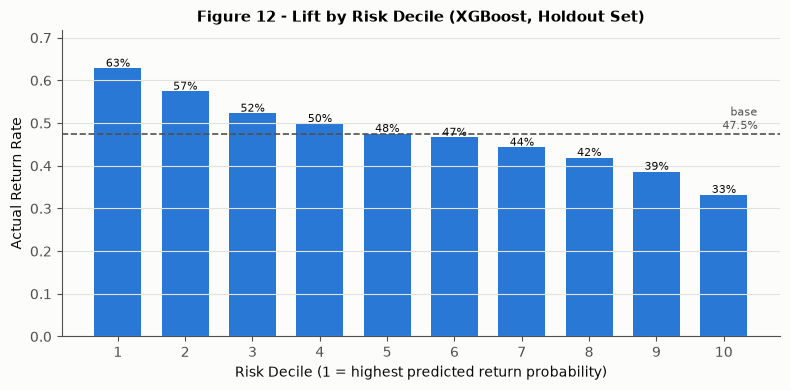

In [32]:
# Figure 12 — Lift by risk decile
fig, ax = plt.subplots(figsize=(8, 4.0))
ax.bar(lift_df['decile'], lift_df['mean'], color=BLUE, width=0.7)
ax.axhline(y_ho.mean(), ls='--', color=INK2, lw=1.2)
ax.text(10.5, y_ho.mean()+0.003, f'base\n{y_ho.mean():.1%}', va='bottom', ha='right', fontsize=8, color=INK2)
for _, row in lift_df.iterrows():
    ax.text(row['decile'], row['mean']+0.004, f"{row['mean']:.0%}", ha='center', fontsize=8, color=INK)
ax.set_xticks(range(1,11))
ax.set_xlabel('Risk Decile (1 = highest predicted return probability)')
ax.set_ylabel('Actual Return Rate')
ax.set_ylim(0, lift_df['mean'].max()+0.09)
ax.set_title(f'Figure 12 - Lift by Risk Decile ({best}, Holdout Set)')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig(FIG_DIR / '12_lift_by_decile.png')
plt.show()


## 24. Checkout vs Post-Delivery Scenario Comparison

| Scenario | `delivery_delay_days` | When usable |
|---|---|---|
| **Post-delivery (PRIMARY)** | Included | After delivery |
| Checkout-time (secondary) | Excluded | At order placement |


In [33]:
best_model_est  = tuned[best][0].named_steps['model']
best_scale_flag = tuned[best][1]

scen_results = {}
print('Scenario comparison (XGBoost, 5-fold CV):\n')
for label, post in [
    ('checkout (excludes delivery_delay_days)', False),
    ('post-delivery (includes delivery_delay_days)', True),
]:
    p = make_pipeline(clone(best_model_est), post, True, best_scale_flag)
    r = cross_validate(p, X_tr, y_tr, cv=cv5,
                       scoring={'roc_auc':'roc_auc','f1':'f1'}, n_jobs=1)
    scen_results[label] = {
        'roc_auc_mean': float(r['test_roc_auc'].mean()),
        'roc_auc_std':  float(r['test_roc_auc'].std()),
        'f1_mean':      float(r['test_f1'].mean()),
    }
    print(f'{label}')
    print(f"  ROC-AUC = {scen_results[label]['roc_auc_mean']:.5f} "
          f"+/- {scen_results[label]['roc_auc_std']:.5f}  "
          f"F1 = {scen_results[label]['f1_mean']:.5f}\n")

diff = (scen_results['post-delivery (includes delivery_delay_days)']['roc_auc_mean']
        - scen_results['checkout (excludes delivery_delay_days)']['roc_auc_mean'])
print(f'AUC gain from delivery_delay_days: +{diff:.5f}')
print('Post-delivery marginally outperforms checkout-time. Post-delivery remains primary scenario.')


Scenario comparison (XGBoost, 5-fold CV):



checkout (excludes delivery_delay_days)
  ROC-AUC = 0.59314 +/- 0.00383  F1 = 0.48907



post-delivery (includes delivery_delay_days)
  ROC-AUC = 0.59454 +/- 0.00345  F1 = 0.49124

AUC gain from delivery_delay_days: +0.00140
Post-delivery marginally outperforms checkout-time. Post-delivery remains primary scenario.


### Cleaning ablation (supplementary)


In [34]:
print('Cleaning ablation (XGBoost, 5-fold CV):\n')
for label, clean in [
    ('impossible values -> NaN + median impute + indicator', True),
    ('raw values (no cleaning)', False),
]:
    p = make_pipeline(clone(best_model_est), POST, clean, best_scale_flag)
    r = cross_validate(p, X_tr, y_tr, cv=cv5, scoring={'roc_auc':'roc_auc'}, n_jobs=1)
    print(f'{label}')
    print(f'  ROC-AUC = {r["test_roc_auc"].mean():.5f} +/- {r["test_roc_auc"].std():.5f}\n')
print('Cleaning does not hurt performance; missing indicators add interpretability.')


Cleaning ablation (XGBoost, 5-fold CV):



impossible values -> NaN + median impute + indicator
  ROC-AUC = 0.59454 +/- 0.00345



raw values (no cleaning)
  ROC-AUC = 0.59500 +/- 0.00331

Cleaning does not hurt performance; missing indicators add interpretability.


## 25. Model Interpretation and Explainability

| Method | Model | What it shows |
|---|---|---|
| LR coefficients / odds ratios | Logistic Regression | Linear associations, standardised |
| Permutation importance | XGBoost (best) | Drop in AUC when feature shuffled |
| SHAP summary | XGBoost (best) | Per-prediction feature contributions |

**Caveat:** All importance measures reflect associations, not causal relationships.


## 26. Logistic Regression Odds Ratios


In [35]:
lr_model = fitted_lr.named_steps['model']
fn_lr    = fitted_lr.named_steps['pre'].get_feature_names_out()
coef_ser = pd.Series(lr_model.coef_[0], index=fn_lr).sort_values()

or_df = pd.DataFrame({'Coefficient': coef_ser.values.round(4),
                       'Odds_Ratio':  np.exp(coef_ser.values).round(4)}, index=coef_ser.index)
print('Top 10 NEGATIVE (reduce return odds):')
print(or_df.head(10).to_string())
print('\nTop 10 POSITIVE (increase return odds):')
print(or_df.tail(10).to_string())


Top 10 NEGATIVE (reduce return odds):
                              Coefficient  Odds_Ratio
shipping_method_same_day          -0.3787      0.6848
shipping_method_standard          -0.3369      0.7140
product_category_electronics      -0.3113      0.7325
device_type_mobile                -0.2825      0.7539
payment_method_debit_card         -0.2763      0.7586
payment_method_paypal             -0.2297      0.7947
product_category_home             -0.1898      0.8271
payment_method_credit_card        -0.1744      0.8400
product_category_sports           -0.1578      0.8541
device_type_tablet                -0.1426      0.8671

Top 10 POSITIVE (increase return odds):
                                         Coefficient  Odds_Ratio
past_return_rate                              0.0017      1.0017
missingindicator_session_length_minutes       0.0135      1.0136
discount_percent                              0.0231      1.0234
expected_prior_returns                        0.0279      1.0283
di

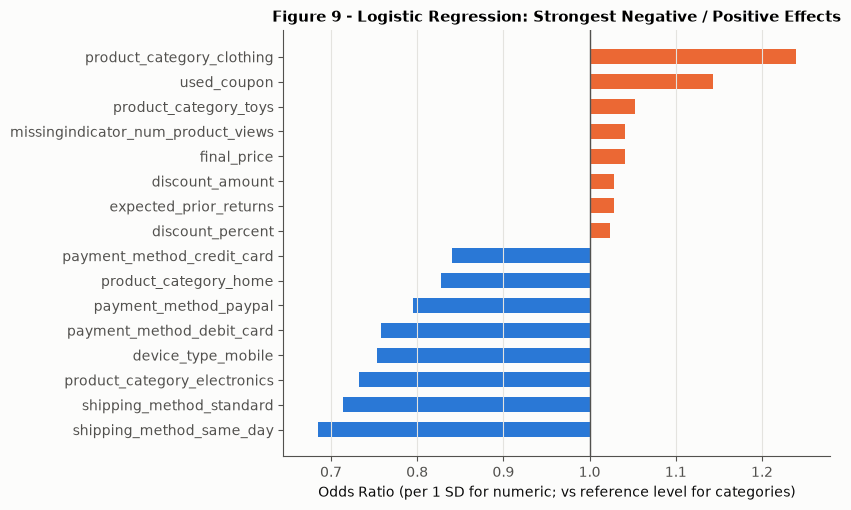

Blue (OR < 1): lower predicted return risk
Orange (OR > 1): higher predicted return risk


In [36]:
# Figure 09 — LR Odds Ratios
top_bot = pd.concat([coef_ser.head(8), coef_ser.tail(8)])
ors     = np.exp(top_bot.values)
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(top_bot.index, ors-1, left=1,
        color=[BLUE if v < 0 else ORANGE for v in top_bot.values], height=0.6)
ax.axvline(1, color=INK2, lw=1)
ax.set_xlim(min(ors)-0.04, max(ors)+0.04)
ax.set_xlabel('Odds Ratio (per 1 SD for numeric; vs reference level for categories)')
ax.set_title('Figure 9 - Logistic Regression: Strongest Negative / Positive Effects')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.savefig(FIG_DIR / '09_lr_odds_ratios.png')
plt.show()
print('Blue (OR < 1): lower predicted return risk')
print('Orange (OR > 1): higher predicted return risk')


## 27. Permutation Importance (XGBoost)

Drop in holdout ROC-AUC when each feature's values are randomly shuffled.  
A large drop = feature is important; near-zero = model barely uses it.


In [37]:
Xs = X_ho.sample(min(10_000, len(X_ho)), random_state=SEED)
ys = y_ho[X_ho.index.get_indexer(Xs.index)]

pi  = permutation_importance(fitted_best, Xs, ys, scoring='roc_auc',
                              n_repeats=10, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({'mean': pi.importances_mean, 'std': pi.importances_std},
                    index=Xs.columns).sort_values('mean')

print('Top 10 features by permutation importance (AUC drop):')
print(imp.tail(10).round(5).to_string())


Top 10 features by permutation importance (AUC drop):
                           mean      std
discount_percent        0.00217  0.00089
product_price           0.00217  0.00118
session_length_minutes  0.00287  0.00081
delivery_delay_days     0.00387  0.00131
past_purchase_count     0.00641  0.00149
payment_method          0.00981  0.00268
used_coupon             0.01196  0.00178
device_type             0.01679  0.00290
product_category        0.01788  0.00228
shipping_method         0.01971  0.00282


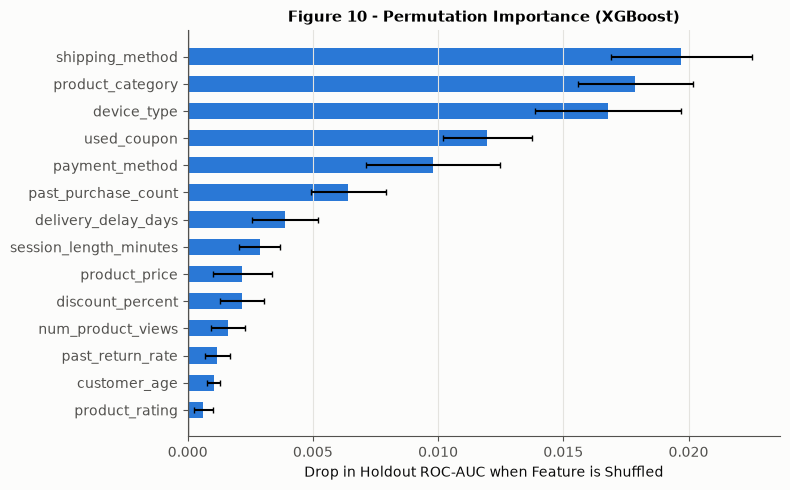

In [38]:
# Figure 10 — Permutation importance
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp['mean'], xerr=imp['std'], color=BLUE, height=0.6, capsize=2)
ax.axvline(0, color=INK2, lw=1)
ax.set_xlabel('Drop in Holdout ROC-AUC when Feature is Shuffled')
ax.set_title(f'Figure 10 - Permutation Importance ({best})')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.savefig(FIG_DIR / '10_permutation_importance.png')
plt.show()


## 28. SHAP Summary (XGBoost)

SHAP provides per-prediction feature contributions.  
Positive SHAP values push toward 'returned'; negative toward 'not returned'.


Top 15 features by mean |SHAP|:
shipping_method_express         0.11755
used_coupon                     0.11677
past_purchase_count             0.07795
product_category_electronics    0.07147
device_type_mobile              0.06488
payment_method_apple_pay        0.06484
delivery_delay_days             0.05605
device_type_desktop             0.04847
product_category_clothing       0.04755
product_category_home           0.03169
payment_method_debit_card       0.03151
product_category_toys           0.02626
discount_percent                0.02583
discount_amount                 0.02495
session_length_minutes          0.02271


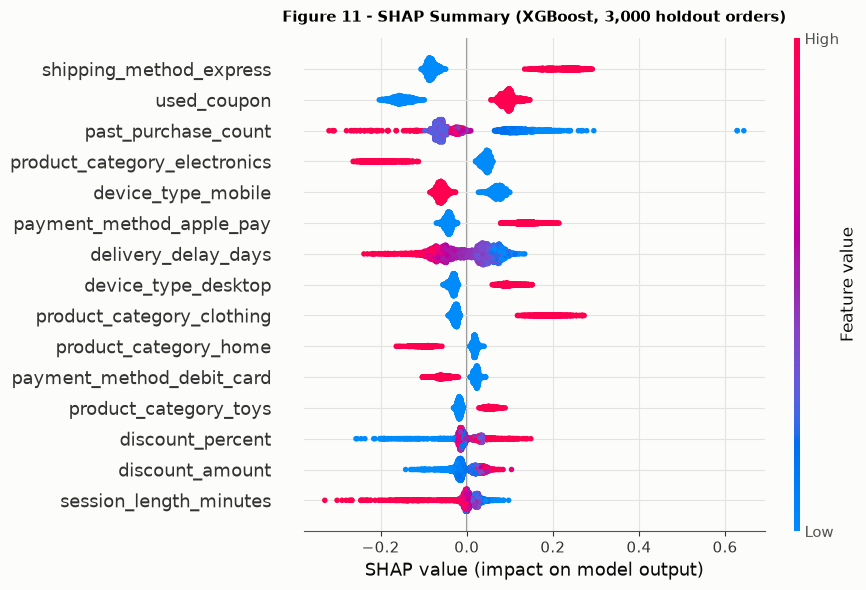

SHAP summary saved.


In [39]:
try:
    import shap
    Xs_shap = X_ho.sample(3000, random_state=SEED)
    Xt_shap = pd.DataFrame(
        fitted_best[:-1].transform(Xs_shap),
        columns=fitted_best.named_steps['pre'].get_feature_names_out()
    )
    explainer = shap.TreeExplainer(fitted_best.named_steps['model'])
    sv = explainer.shap_values(Xt_shap)
    if isinstance(sv, list): sv = sv[1]
    if sv.ndim == 3:         sv = sv[:, :, 1]

    mean_abs = pd.Series(np.abs(sv).mean(0), index=Xt_shap.columns)
    print('Top 15 features by mean |SHAP|:')
    print(mean_abs.sort_values(ascending=False).head(15).round(5).to_string())

    plt.figure(figsize=(9, 6))
    shap.summary_plot(sv, Xt_shap, max_display=15, show=False, plot_size=None)
    plt.title(f'Figure 11 - SHAP Summary ({best}, 3,000 holdout orders)', fontweight='bold', pad=12)
    plt.tight_layout()
    plt.savefig(FIG_DIR / '11_shap_summary.png')
    plt.show()
    print('SHAP summary saved.')
except Exception as e:
    print(f'SHAP note: {e}')
    print('If shap is not installed, run: pip install shap')


## 29. Final Test Set Predictions

Final XGBoost model re-trained on the complete 200k labelled dataset, applied to `test.csv`.

| Output file | Columns | Description |
|---|---|---|
| `results/submission.csv` | `ID`, `returned` | Binary prediction (threshold 0.50) |
| `results/test_probabilities.csv` | `ID`, `return_probability` | Continuous probability score |


In [40]:
print('Re-training on full 200k labelled dataset...')
final_model = clone(tuned[best][0]).fit(X, y)

X_test = test.drop(columns=[ID_COL])
pt     = final_model.predict_proba(X_test)[:, 1]

submission    = pd.DataFrame({'ID': test[ID_COL], 'returned': (pt >= OP_THR).astype(int)})
probabilities = pd.DataFrame({'ID': test[ID_COL], 'return_probability': pt})

submission.to_csv(OUT_DIR / 'submission.csv',            index=False)
probabilities.to_csv(OUT_DIR / 'test_probabilities.csv', index=False)

print(f'submission.csv         : {len(submission):,} rows, cols={list(submission.columns)}')
print(f'  Predicted returns    : {submission["returned"].sum():,} ({submission["returned"].mean():.2%})')
print(f'test_probabilities.csv : {len(probabilities):,} rows, cols={list(probabilities.columns)}')
print(f'  Probability range    : [{pt.min():.4f}, {pt.max():.4f}]')
print(f'  IDs match test.csv   : {(submission["ID"].values == test[ID_COL].values).all()}')
print(f'\nOutput files saved to: {OUT_DIR.resolve()}')
print('\nFirst 5 rows of submission.csv:')
print(submission.head().to_string(index=False))


Re-training on full 200k labelled dataset...


submission.csv         : 50,000 rows, cols=['ID', 'returned']
  Predicted returns    : 18,622 (37.24%)
test_probabilities.csv : 50,000 rows, cols=['ID', 'return_probability']
  Probability range    : [0.2006, 0.7863]
  IDs match test.csv   : True

Output files saved to: C:\Users\Lenovo\Desktop\PREDICTIVE PROJECT\CODE\results

First 5 rows of submission.csv:
    ID  returned
 38683         0
 64939         0
  3954         0
120374         1
172861         0


## 30. Sample Prediction Demonstration

Five real orders from the holdout set — the model's probability output is shown alongside the actual outcome.

This section demonstrates the pipeline produces predictions. It is **not** an interactive application.


In [41]:
sample_idx    = X_ho.sample(5, random_state=SEED).index
sample_proba  = fitted_best.predict_proba(X_ho.loc[sample_idx])[:, 1]
sample_pred   = (sample_proba >= OP_THR).astype(int)
sample_actual = y_ho[X_ho.index.get_indexer(sample_idx)]
sample_ids    = train.loc[sample_idx, ID_COL].values

demo_df = pd.DataFrame({
    'Order ID':           sample_ids,
    'Return Probability': [f'{p:.2%}' for p in sample_proba],
    'Prediction':         ['Returned' if p == 1 else 'Not Returned' for p in sample_pred],
    'Actual':             ['Returned' if a == 1 else 'Not Returned' for a in sample_actual],
    'Correct?':           ['Y' if p == a else 'N' for p, a in zip(sample_pred, sample_actual)],
})
print('Sample predictions (5 real holdout orders):\n')
print(demo_df.to_string(index=False))
print()
print('Return Probability = raw predict_proba() output.')
print(f'Prediction applies operating threshold of {OP_THR}.')
print('Actual = true label from holdout set.')


Sample predictions (5 real holdout orders):

 Order ID Return Probability   Prediction       Actual Correct?
    11539             57.92%     Returned     Returned        Y
   101626             31.93% Not Returned     Returned        N
    75070             45.22% Not Returned Not Returned        Y
   167148             47.88% Not Returned     Returned        N
    28054             57.94%     Returned     Returned        Y

Return Probability = raw predict_proba() output.
Prediction applies operating threshold of 0.5.
Actual = true label from holdout set.


In [42]:
# Single-order deep-dive
one_order = X_ho.loc[[sample_idx[0]]]
raw_proba = fitted_best.predict_proba(one_order)
print(f'Order ID          : {train.loc[sample_idx[0], ID_COL]}')
print(f'predict_proba()   : {raw_proba}  -> [P(not returned), P(returned)]')
print(f'Return probability: {raw_proba[0,1]:.4f} = {raw_proba[0,1]:.2%}')
print(f'Prediction (>={OP_THR}): {"Returned" if raw_proba[0,1] >= OP_THR else "Not Returned"}')


Order ID          : 11539
predict_proba()   : [[0.4208473 0.5791527]]  -> [P(not returned), P(returned)]
Return probability: 0.5792 = 57.92%
Prediction (>=0.5): Returned


## 31. KDD Process Mapping

| KDD Step | This Project |
|---|---|
| **1. Selection** | Kaggle e-commerce dataset: 200k orders, 14 features, binary target |
| **2. Pre-processing** | 6 features with impossible values (~32% rows); NaN + median impute + indicator |
| **3. Transformation** | 5 engineered features; OHE for categoricals; StandardScaler for LR |
| **4. Data Mining** | 5 classifiers + baseline tuned via 3-fold GridSearchCV; selected by 5-fold CV AUC |
| **5. Interpretation** | LR odds ratios, permutation importance, SHAP; threshold analysis; lift; bootstrap CIs |

All steps implemented in sklearn Pipelines — reproducible, leakage-free, portable.


## 32. Business Interpretation

### What drives returns in this dataset?

From permutation importance and SHAP, the top drivers are:

1. **shipping_method** — Express shipping is associated with the highest return rate (~53%) vs same-day (~44%) or standard (~46%). Express shoppers may make more impulse purchases.
2. **product_category** — Clothing has the highest return rate (~53%); electronics the lowest (~42%). Consistent with industry-wide fit/size patterns.
3. **device_type** — Desktop users return more (~52%) vs mobile (~45%).
4. **used_coupon** — Coupon users return at a higher rate. Discount-motivated purchases may not satisfy the underlying need.
5. **payment_method** — Apple Pay / credit card users return more; debit card users return least.

### Business recommendations

- **Targeting:** Flag top-10% highest-risk orders weekly. Focus interventions (post-purchase emails, size/fit guidance for clothing) on this group.
- **Category policy:** Electronics returns are genuinely lower — concentrate return-prevention resources on clothing and toys.
- **Threshold choice:** High-cost interventions (manual inspection) -> use threshold 0.55+. Low-cost interventions (email) -> top-k ranking.

All associations reflect learned patterns, not causal relationships.


## 33. Results and Discussion


In [43]:
print('=== RESULTS SUMMARY ===\n')
print('5-Fold CV ROC-AUC (160k training rows):')
for name in order_models:
    m = cvres[name]
    marker = '  <- SELECTED' if name == best else ''
    print(f'  {name:35s}: {m["roc_auc"]["mean"]:.5f} +/- {m["roc_auc"]["std"]:.5f}{marker}')

print('\nHoldout performance (40k rows, threshold 0.50):')
for name in order_models:
    m = ho_results[name]
    marker = '  <- SELECTED' if name == best else ''
    print(f'  {name:35s}: AUC={m["roc_auc"]:.5f}  F1={m["f1"]:.4f}  Acc={m["accuracy"]:.4f}{marker}')

print('\nScenario comparison (XGBoost, 5-fold CV):')
for label, res in scen_results.items():
    print(f'  {label}: AUC={res["roc_auc_mean"]:.5f} +/- {res["roc_auc_std"]:.5f}  F1={res["f1_mean"]:.5f}')

print('\nThreshold analysis:')
print(f'  F1-optimal threshold (OOF) : {best_thr:.4f}  (flags {(oof >= best_thr).mean():.2%} -- REJECTED)')
print(f'  Operating threshold        : {OP_THR}')

print('\nLift analysis (holdout):')
print(f'  Overall return rate    : {y_ho.mean():.4f}')
print(f'  Top-10% return rate    : {top10_rate:.4f}')
print(f'  Top-10% lift           : {top10_lift:.4f}x')

print('\nTest set predictions:')
print(f'  Orders scored          : {len(pt):,}')
print(f'  Predicted return share : {(pt >= OP_THR).mean():.2%}')


=== RESULTS SUMMARY ===

5-Fold CV ROC-AUC (160k training rows):
  Baseline (majority class)          : 0.50000 +/- 0.00000
  Logistic Regression                : 0.58946 +/- 0.00386
  Decision Tree                      : 0.57741 +/- 0.00286
  Random Forest                      : 0.59092 +/- 0.00381
  Hist Gradient Boosting             : 0.59380 +/- 0.00324
  XGBoost                            : 0.59454 +/- 0.00345  <- SELECTED

Holdout performance (40k rows, threshold 0.50):
  Baseline (majority class)          : AUC=0.50000  F1=0.0000  Acc=0.5254
  Logistic Regression                : AUC=0.59077  F1=0.4900  Acc=0.5672
  Decision Tree                      : AUC=0.57556  F1=0.4392  Acc=0.5555
  Random Forest                      : AUC=0.59318  F1=0.4476  Acc=0.5697
  Hist Gradient Boosting             : AUC=0.59437  F1=0.4905  Acc=0.5696
  XGBoost                            : AUC=0.59543  F1=0.4935  Acc=0.5710  <- SELECTED

Scenario comparison (XGBoost, 5-fold CV):
  checkout (exclude

### Why performance is moderate

- No single feature has individual AUC above 0.527.
- All feature-target Pearson correlations are |r| < 0.06.
- The feature set lacks rich signals: product return history, review text, detailed product specs.
- Individual return decisions depend on subjective preferences not captured by structured transactional data.

### Value as a risk-ranking tool

Despite moderate flat accuracy, the model identifies a high-risk subgroup:  
top-10% orders have ~63% return rate vs ~47.5% overall — **lift ~1.33x**.  
This is practically useful for targeted operations.


## 34. Limitations

1. **Invalid values (~32%):** Root cause unknown; median imputation handles them but does not explain the underlying data quality issue.
2. **Moderate performance:** Best model ROC-AUC ~0.596; only slightly above baseline.
3. **Limited features:** No product return history, review sentiment, or detailed product specs.
4. **No test labels:** `test.csv` has no `returned` column; holdout is the best unbiased estimate.
5. **Feature availability:** `delivery_delay_days` is only available post-delivery; production deployment must choose the appropriate scenario.
6. **No temporal ordering:** Dataset lacks timestamps; time-based splits preferred in production.
7. **Past return rate assumption:** Treated as computed from prior orders only; not documented in the dataset.


## 35. Future Work

1. **Richer features:** Product return history at SKU level, review sentiment scores, product images.
2. **Time-based cross-validation:** `TimeSeriesSplit` when timestamps become available.
3. **Probability calibration:** `CalibratedClassifierCV` for well-calibrated production probabilities.
4. **Cost-sensitive learning:** Optimise threshold to minimise expected cost when FP/FN costs are known.
5. **Online learning:** Incremental model updates as new return data arrives.


## 36. Conclusion

This project implemented an end-to-end KDD / Predictive Analytics workflow for e-commerce product return prediction.

**Key findings:**

1. Dataset is approximately balanced (~47.5% return rate); ~32% of rows contain physically impossible values, handled via NaN conversion and median imputation with missing-value indicators.
2. No individual feature is a strong predictor (max single-feature AUC ~0.527). Categorical features show small but significant associations (Cramer's V 0.06-0.08).
3. **XGBoost** achieved best CV ROC-AUC (~0.595), selected as final model.
4. Holdout: ROC-AUC ~0.596, accuracy ~57%, F1 ~0.493 — meaningful improvement over baseline.
5. Post-delivery scenario marginally outperforms checkout-time (confirms small value of delivery delay).
6. F1-optimal threshold (~0.34) rejected — collapses to trivial rule. Operating threshold: 0.50.
7. **Most valuable as a risk-ranking tool:** top-10% risk group has ~63% return rate vs ~47.5% overall — lift ~1.33x.
8. Shipping method, product category, device type, and payment method are the strongest predictors.


## 37. References

1. Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD*, 785-794.
2. Fayyad, U., Piatetsky-Shapiro, G., & Smyth, P. (1996). From data mining to knowledge discovery in databases. *AI Magazine*, 17(3), 37-54.
3. Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics*, 29(5), 1189-1232.
4. Lundberg, S. M., & Lee, S. I. (2017). A unified approach to interpreting model predictions. *NeurIPS*, 30.
5. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825-2830.
6. Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.
7. Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful. *JMLR*, 20(177).
8. Dataset: hakdevelopment. *E-Commerce Dataset*. Kaggle. https://www.kaggle.com/datasets/hakdevelopment/e-commerce-dataset


### Supplementary: Bootstrap Confidence Intervals


In [44]:
rng  = np.random.default_rng(SEED)
B    = 300
idx  = np.arange(len(y_ho))
boot = {'best_auc':[], 'lr_auc':[], 'diff':[], 'best_f1':[], 'top10_rate':[]}

print(f'Running {B} bootstrap resamples...')
for _ in range(B):
    s  = rng.choice(idx, len(idx), replace=True)
    a1 = roc_auc_score(y_ho[s], probs[best][s])
    a2 = roc_auc_score(y_ho[s], probs['Logistic Regression'][s])
    boot['best_auc'].append(a1); boot['lr_auc'].append(a2); boot['diff'].append(a1-a2)
    boot['best_f1'].append(f1_score(y_ho[s], probs[best][s] >= OP_THR))
    ps = probs[best][s]
    boot['top10_rate'].append(y_ho[s][ps >= np.quantile(ps, 0.9)].mean())

ci = lambda v: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))
print(f'Bootstrap 95% CIs ({B} resamples, holdout):')
print(f'  {best} ROC-AUC        : {ci(boot["best_auc"])}')
print(f'  LR ROC-AUC             : {ci(boot["lr_auc"])}')
print(f'  AUC diff (best - LR)   : {ci(boot["diff"])}')
print(f'  {best} F1 @ {OP_THR}  : {ci(boot["best_f1"])}')
print(f'  Top-10% return rate    : {ci(boot["top10_rate"])}')


Running 300 bootstrap resamples...


Bootstrap 95% CIs (300 resamples, holdout):
  XGBoost ROC-AUC        : (0.5906396640402412, 0.6003917384601283)
  LR ROC-AUC             : (0.5858192481974412, 0.5963914579695179)
  AUC diff (best - LR)   : (0.0026083266937407036, 0.006594614572984181)
  XGBoost F1 @ 0.5  : (0.48748785708568687, 0.5005333036806405)
  Top-10% return rate    : (0.6132105572213893, 0.6418395401149712)
